## Figure 1
- a) Hot-only Moratlity Rate Map
- b) Cold-only Moratlity Rate Map
- c) Monthly Global Avg Mortality Rate
- d) Box plot by income

### Initialization

In [7]:
import sys
from pathlib import Path

PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils").is_dir()
)
sys.path.insert(0, str(PROJECT_ROOT))

import importlib
import os
from datetime import UTC, datetime

import cartopy.crs as ccrs
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import xvec
from dotenv import find_dotenv, load_dotenv

from utils import analysis_utils, isku_utils, plotting_utils, stats_utils

importlib.reload(analysis_utils)
importlib.reload(isku_utils)
importlib.reload(plotting_utils)

<module 'utils.plotting_utils' from '/home/emily_zuetell/projects/poreallas/utils/plotting_utils.py'>

In [2]:
load_dotenv(
    find_dotenv("october_local.env", raise_error_if_not_found=True), override=True
)

EFFECTS_URI = os.environ["POREALLAS_EFFECTS_URI"]
IMPACT_REGION_POLYGONS = os.environ["POREALLAS_REGIONS_POLYGONS_URI"]
SOCIOECONOMICS_URI = os.environ["POREALLAS_SOCIOECONOMICS_URI"]

# Climate Data
TAS_FORECAST_URI = os.environ["POREALLAS_TAS_FORECAST_URI"]
ERA5_URI = os.environ["POREALLAS_ERA5_URI"]
TAS_FORECAST_RAW = os.environ["POREALLAS_PARSED_FORECAST_URI"]

In [3]:
# Baseline period for Impact
effect = xr.open_datatree(EFFECTS_URI, consolidated=False)
BASELINE_PERIOD = analysis_utils.get_baseline_period(effect, years=30)
# Define Forecast Months
FC_MONTHS = [10, 11, 12, 1, 2, 3]
FC_PERIOD = slice("2026-10-01", "2027-03-31")

config = analysis_utils.ImpactConfig(
    version=f"v{datetime.now(tz=UTC):%y%m%d}",
    baseline_period=BASELINE_PERIOD,
    polygons_path=os.environ["POREALLAS_REGIONS_POLYGONS_URI"],
    socioeconomics_path=os.environ["POREALLAS_SOCIOECONOMICS_URI"],
    rate=True,
    age_weight=True,
    months=FC_MONTHS,
    hotonly="hotonly",
    dims=["number", "sample"],
)

## Figure 1

Main Results Fig

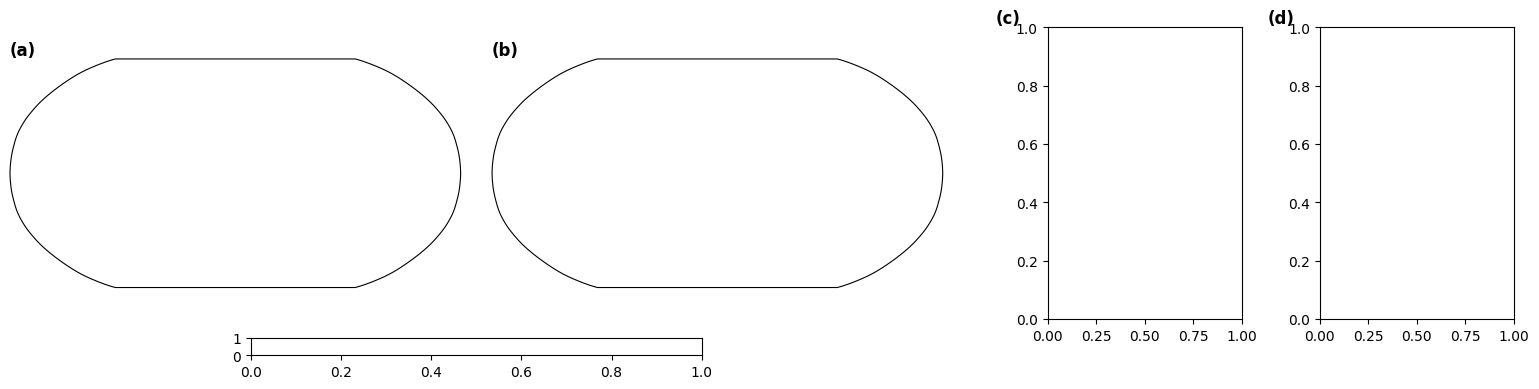

In [8]:
### Build Gridspec ###
fig = plt.figure(figsize=(16, 4))
gs = fig.add_gridspec(
    1,
    2,
    width_ratios=[2, 1],   # 1 = 0.5 + 0.5 from before
    wspace=0.15,
    left=0.03,
    right=0.97,
    top=0.90,
    bottom=0.08,
)

# ---- (a), (b) + shared colorbar ----
gs_mid = gs[0].subgridspec(2, 4, height_ratios=[1, 0.06], hspace=0.12, wspace=0.15)
ax_b = fig.add_subplot(gs_mid[0, :2], projection=ccrs.Robinson())
ax_c = fig.add_subplot(gs_mid[0, 2:], projection=ccrs.Robinson())
cax_bc = fig.add_subplot(gs_mid[1, 1:3])

# ---- (c), (d) ----
# Matching height_ratios keeps (f)/(g) aligned with the maps, not the colorbar
gs_cd = gs[1].subgridspec(2, 2, height_ratios=[1, 0.06], hspace=0.12, wspace=0.4)  # increase this
ax_timeseries = fig.add_subplot(gs_cd[0, 0])
ax_extra = fig.add_subplot(gs_cd[0, 1])

# ---- Panel labels ----
for label, a in zip("ab", [ax_b, ax_c]):
    a.text(
        0.0,
        1.0,
        f"({label})",
        transform=a.transAxes,
        fontsize=12,
        fontweight="bold",
        va="bottom",
        ha="left",
    )
for label, a in zip("cd", [ax_timeseries, ax_extra]):
    a.text(
        -0.27,
        1.0,
        f"({label})",
        transform=a.transAxes,
        fontsize=12,
        fontweight="bold",
        va="bottom",
        ha="left",
    )

In [9]:
# Compute the Mortality Impact relative to a Baseline Period for the Projected Effects
month_order = config.months
cmap = plt.get_cmap("coolwarm")
colors = {"hotonly": mcolors.to_hex(cmap(0.85)), "coldonly": mcolors.to_hex(cmap(0.15))}
ax = ax_timeseries
for hotonly in ["hotonly", "coldonly"]:
    impact = analysis_utils.compute_impact(
        effect.chunk({dim: -1 for dim in config.dims}),
        config,
        hotonly=hotonly,
        ensemble=True,
    )
    ## Global Pop-Weighted ##
    da = impact.sel(month=config.months)
    pop = config.socioeconomics.pop.sel(region=da.region).fillna(0)
    da = da.weighted(pop).mean(dim="region")
    da = da.assign_coords(
        month=range(len(config.months))
    )  # 0..5 positions instead of real month values

    q = da.quantile([0.05, 0.95], dim=["number", "sample"]).compute()
    ax.fill_between(
        da.month,
        q.sel(quantile=0.05),
        q.sel(quantile=0.95),
        color=colors[hotonly],
        alpha=0.25,
        linewidth=0,
        zorder=1,
    )
    da.mean(dim=["number", "sample"]).plot(
        marker="o", ax=ax, label=hotonly, color=colors[hotonly], zorder=10
    )

ax.axhline(y=0, color="black", linewidth=0.5)
ax.set_xticks(range(len(month_order)))
ax.set_xticklabels(month_order)
ax.set_xlabel("Month")
ax.set_ylabel("6-month Mortality Rate \n[deaths/100k]")
names = {"hotonly": "Hot Deaths", "coldonly": "Cold Deaths"}
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, [names.get(l, l) for l in labels], frameon=False)
ax.set_title("")

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


Text(0.5, 1.0, '')

In [10]:
### Maps ###
# Compute fields
results = {}
for hotonly in ["hotonly", "coldonly"]:
    impact = analysis_utils.compute_impact(
        effect.chunk({dim: -1 for dim in config.dims}),
        config,
        ensemble=True,
        hotonly=hotonly,
    )
    gdf = config.polygons.reset_index()
    gdf["geometry"] = gdf.geometry.make_valid()
    # select only 6-month forecast
    ds = impact.sel(month=config.months)

    geoms = gdf.set_index("region").loc[ds["region"].values, "geometry"]

    ds = (
        ds.assign_coords(geometry=("region", geoms.values))
        .swap_dims(region="geometry")
        .xvec.set_geom_indexes("geometry", crs=gdf.crs)
    )

    ds_6 = ds.sum(dim=["month"])  # 6-month total
    ens_mean = ds_6.mean(dim=["sample", "number"])  # ensemble mean
    results[hotonly] = (ds_6, ens_mean)


def make_norm(means, step=5):
    all_abs = np.concatenate([abs(m).values.ravel() for m in means])
    vmax = np.ceil(np.nanquantile(all_abs, 0.98) / step) * step
    levels = np.round(np.arange(-vmax, vmax + step / 2, step), 10)
    cmap = plt.get_cmap("RdBu_r", len(levels) - 1 + 2)
    norm = mcolors.BoundaryNorm(levels, cmap.N, extend="both")
    return levels, cmap, norm


scale = make_norm([results["hotonly"][1], results["coldonly"][1]])

panels = [(ax_b, "hotonly"), (ax_c, "coldonly")]
levels, cmap, norm = scale

for ax, hotonly in panels:
    ds_6, ens_mean = results[hotonly]

    gdf_plot = ens_mean.xvec.to_geodataframe(name="anom").to_crs(
        ax.projection.proj4_init
    )
    gdf_plot.plot(column="anom", ax=ax, cmap=cmap, norm=norm, linewidth=0)

    ax.coastlines(linewidth=0.6, color="k")
    ax.set_extent([-180, 180, -60, 90], crs=ccrs.PlateCarree())
    ax.spines["geo"].set_visible(False)
    mask = stats_utils.region_ttest_mask(ds_6, alpha=0.05)
    plotting_utils.add_polygons(ax, mask, transform=ccrs.PlateCarree())
    ax.set_axis_off()

# Colorbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(
    sm,
    cax=cax_bc,
    orientation="horizontal",
    extend="both",
    label="Mortality Rate (deaths/100k)",
)
cbar.set_ticks(levels[::2])

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_

In [11]:
def weighted_box_stats(vals, weights, whis=1.5):
    # weights = pop/pop_box
    mask = np.isfinite(vals) & np.isfinite(weights)
    v, w = vals[mask], weights[mask]
    order = np.argsort(v)
    v, w = v[order], w[order]
    # Normalize weights within box
    cdf = (np.cumsum(w) - 0.5 * w) / w.sum()
    q1, med, q3 = np.interp([0.25, 0.5, 0.75], cdf, v)
    iqr = q3 - q1
    whislo = v[v >= q1 - whis * iqr].min()
    whishi = v[v <= q3 + whis * iqr].max()
    return {
        "med": med,
        "q1": q1,
        "q3": q3,
        "whislo": whislo,
        "whishi": whishi,
        "fliers": [],
    }

In [12]:
### Box Plot ###
quartile_labels = [
    "Low income",
    "Low-middle income",
    "Middle-high income",
    "High income",
]
quartile_labels_display = [lbl.replace(" ", "\n", 1) for lbl in quartile_labels]

data_by_category = {}
for hotonly in ["hotonly", "coldonly"]:
    impact = analysis_utils.compute_impact(
        effect.chunk({dim: -1 for dim in config.dims}),
        config,
        ensemble=False,
        hotonly=hotonly,
    )
    impact = impact.sel(month=config.months)
    # 6-month total impact
    impact_mean = impact.sum(dim="month")
    if "number" in impact_mean.dims or "sample" in impact_mean.dims:
        impact_mean = impact_mean.mean(
            dim=[d for d in ["number", "sample"] if d in impact_mean.dims]
        )

    impact_aligned, gdppc_aligned = xr.align(
        impact_mean, config.socioeconomics.gdppc, join="inner"
    )
    region_vals = impact_aligned.values

    pop_aligned = config.socioeconomics.pop.sel(region=impact_aligned.region)

    sort_idx = np.argsort(gdppc_aligned.values)
    gdppc_sorted = gdppc_aligned.values[sort_idx]
    pop_sorted = pop_aligned.values[sort_idx]
    # Equal-Population Bins
    cum_pop = np.cumsum(pop_sorted)
    cum_pop_frac = cum_pop / cum_pop[-1]
    breakpoints = np.interp([0.25, 0.5, 0.75], cum_pop_frac, gdppc_sorted)
    bin_edges = np.concatenate(
        [[gdppc_sorted[0] - 1], breakpoints, [gdppc_sorted[-1] + 1]]
    )
    # Cut GDP Quartiles
    quartiles = pd.cut(gdppc_aligned.values, bins=bin_edges, labels=quartile_labels)
    # Within-bin weighting
    pop_vals = pop_aligned.values
    data_by_category[hotonly] = [
        weighted_box_stats(region_vals[quartiles == q], pop_vals[quartiles == q])
        for q in quartile_labels
    ]

ax = ax_extra
positions = []
box_data = []
group_gap = 1
box_width = 0.6
n_quartiles = 4

for i, category in enumerate(["hotonly", "coldonly"]):
    for j, q_data in enumerate(data_by_category[category]):
        positions.append(i * (n_quartiles + group_gap) + j)
        box_data.append(q_data)

bp = ax.bxp(
    box_data,
    positions=positions,
    widths=box_width,
    patch_artist=True,
    medianprops={"color": "black"},
    showfliers=False,
)

for patch, color in zip(
    bp["boxes"],
    [colors[c] for c in ["hotonly", "coldonly"] for _ in range(n_quartiles)],
):
    patch.set_facecolor(color)

group_centers = [
    i * (n_quartiles + group_gap) + (n_quartiles - 1) / 2 for i in range(2)
]

ax.set_ylim(-30, 30)
ax.set_xticks(positions)
ax.set_xticklabels(["L", "LM", "UM", "H"] * 2, fontsize=7, rotation=45)
ax.tick_params(axis="x", length=0)

ax.axhline(y=0, color="black", linewidth=0.5)
ax.set_ylabel("6-month Mortality Rate \n[deaths/100k]")

sec = ax.secondary_xaxis(-0.2)
sec.set_xticks(group_centers)
sec.set_xticklabels(["Hot", "Cold"])
sec.tick_params(length=0)

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


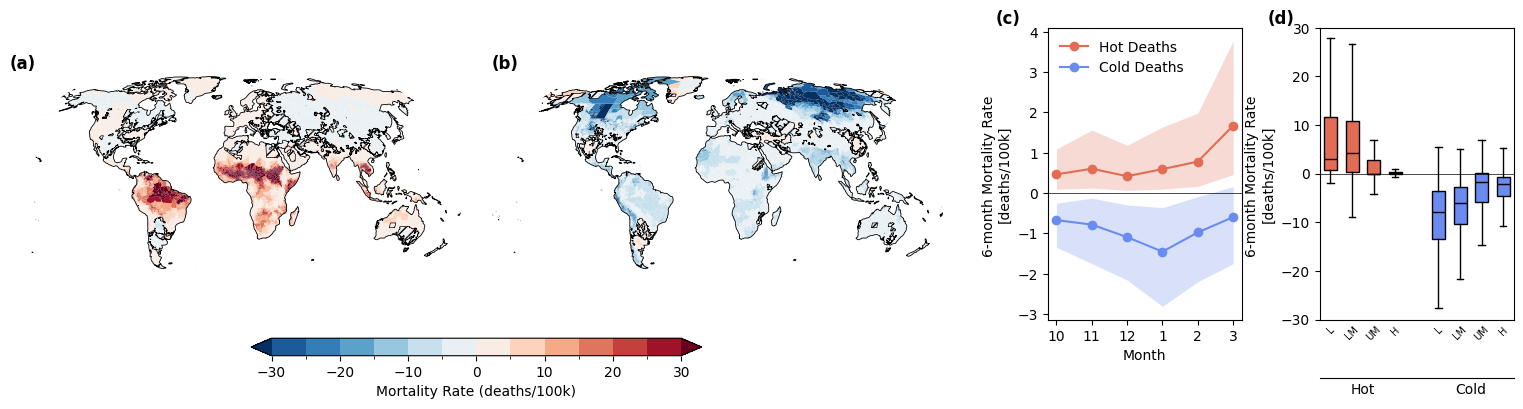

In [13]:
fig

In [ ]:
fig.savefig(f"{config.version}_fig02_2610.png", dpi=600, bbox_inches="tight")